In [1]:
import numpy as np
import pandas as pd
import os
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torch.utils.data import WeightedRandomSampler
from torch.optim.lr_scheduler import CosineAnnealingLR
from collections import Counter
import copy, time

In [2]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
tushar5harma_plant_village_dataset_updated_path = kagglehub.dataset_download('tushar5harma/plant-village-dataset-updated')
shubham2703_five_crop_diseases_dataset_path = kagglehub.dataset_download('shubham2703/five-crop-diseases-dataset')
zunorain_pea_plant_dataset_path = kagglehub.dataset_download('zunorain/pea-plant-dataset')
nirmalsankalana_grape400_dataset_path = kagglehub.dataset_download('nirmalsankalana/grape400-dataset')
mexwell_crop_diseases_classification_path = kagglehub.dataset_download('mexwell/crop-diseases-classification')
ayushbpanchal_cashew_image_dataset_path = kagglehub.dataset_download('ayushbpanchal/cashew-image-dataset')
tahmidmir_pumpkin_leaf_diseases_dataset_from_bangladesh_path = kagglehub.dataset_download('tahmidmir/pumpkin-leaf-diseases-dataset-from-bangladesh')
fahadbd_plant_leaf_freshness_path = kagglehub.dataset_download('fahadbd/plant-leaf-freshness')
binnassor89_melon_macronutrient_deficiency_dataset_path = kagglehub.dataset_download('binnassor89/melon-macronutrient-deficiency-dataset')
asadullahgalib_guava_disease_dataset_path = kagglehub.dataset_download('asadullahgalib/guava-disease-dataset')
nirmalsankalana_rocole_a_robusta_coffee_leaf_images_dataset_path = kagglehub.dataset_download('nirmalsankalana/rocole-a-robusta-coffee-leaf-images-dataset')
mahmoudshaheen1134_lemon_leaf_disease_dataset_lldd_path = kagglehub.dataset_download('mahmoudshaheen1134/lemon-leaf-disease-dataset-lldd')
shuvokumarbasak4004_flower_leaf_diseases_dataset_new_and_update_path = kagglehub.dataset_download('shuvokumarbasak4004/flower-leaf-diseases-dataset-new-and-update')
mihsanpermana_vanilla_plant_disease_image_dataset_path = kagglehub.dataset_download('mihsanpermana/vanilla-plant-disease-image-dataset')
tushar5harma_plant_village_dataset_updated_path = kagglehub.dataset_download('tushar5harma/plant-village-dataset-updated')
nirmalsankalana_rocole_a_robusta_coffee_leaf_images_dataset_path = kagglehub.dataset_download('nirmalsankalana/rocole-a-robusta-coffee-leaf-images-dataset')
ayushbpanchal_cashew_image_dataset_path = kagglehub.dataset_download('ayushbpanchal/cashew-image-dataset')


print('Data source import complete.')

Data source import complete.


In [3]:
for entry in sorted(os.listdir("/kaggle/input/datasets")):
    print(entry)

adilmubashirchaudhry
asadullahgalib
ayushbpanchal
binnassor89
fahadbd
mahmoudshaheen1134
mexwell
mihsanpermana
nirmalsankalana
shubham2703
shuvokumarbasak4004
tahmidmir
tushar5harma
yasaminborhani
zunorain


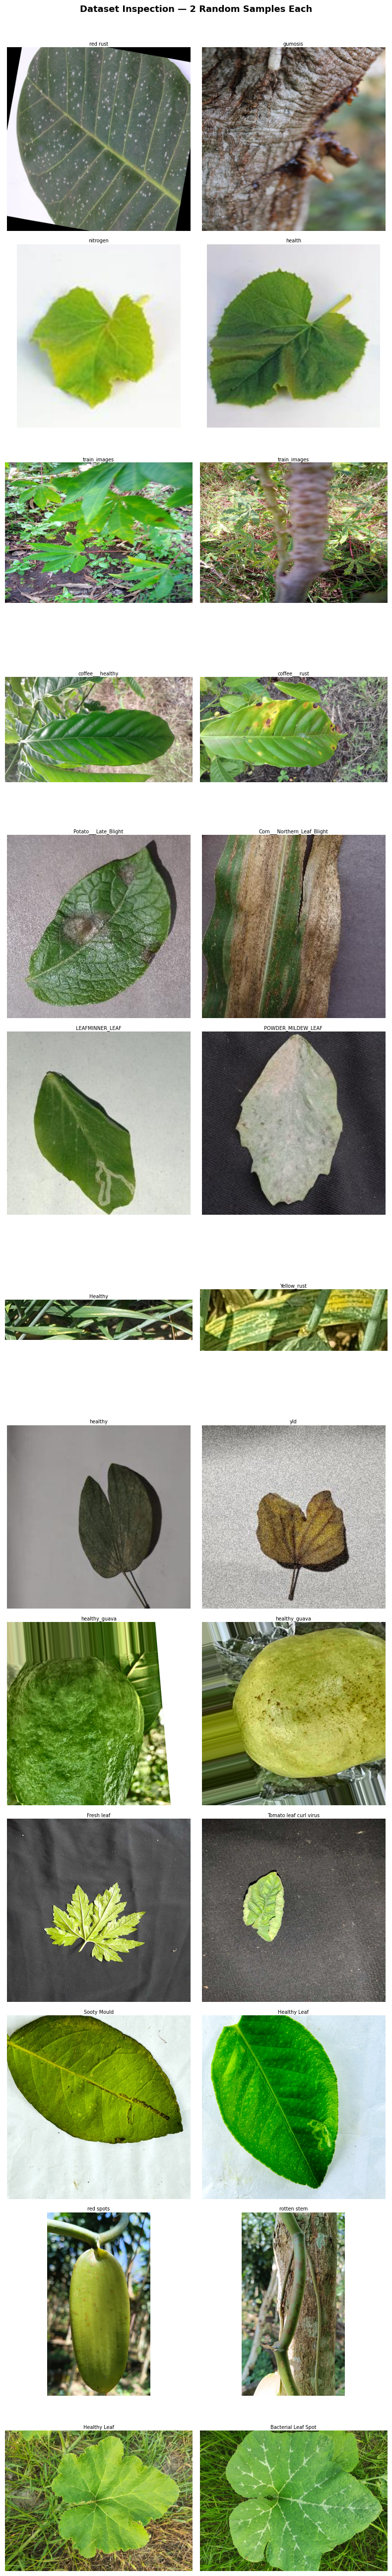

In [3]:
BASE = "/kaggle/input/datasets"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ── All datasets to inspect ───────────────────────────────────────────────────
DATASETS = {
    # ✅ Confirmed Phase 2
    "Cashew (ayushbpanchal)"           : f"{BASE}/ayushbpanchal",
    "Melon Deficiency (binnassor89)"   : f"{BASE}/binnassor89",
    "Crop Diseases (mexwell)"          : f"{BASE}/mexwell",
    "RoCoLe Coffee (nirmalsankalana)"  : f"{BASE}/nirmalsankalana",
    "Five Crop Diseases (shubham2703)" : f"{BASE}/shubham2703",
    "Pea Plant (zunorain)"             : f"{BASE}/zunorain",
    # 🔍 Wheat rust substitute candidate
    "WheatRust? (yasaminborhani)"      : f"{BASE}/yasaminborhani",
    # ❌ Excluded per Notion (but inspect to confirm)
    "Flower Leaf (shuvokumarbasak4004)": f"{BASE}/shuvokumarbasak4004",
    # ❓ Unknown — identify these
    "Unknown (asadullahgalib)"         : f"{BASE}/asadullahgalib",
    "Unknown (fahadbd)"                : f"{BASE}/fahadbd",
    "Unknown (mahmoudshaheen1134)"     : f"{BASE}/mahmoudshaheen1134",
    "Unknown (mihsanpermana)"          : f"{BASE}/mihsanpermana",
    "Unknown (tahmidmir)"              : f"{BASE}/tahmidmir",
}

# ── Find random images anywhere under root ────────────────────────────────────
def find_random_images(root: str, n: int = 2):
    root = Path(root)
    if not root.exists():
        return None, f"PATH NOT FOUND"

    all_images = [
        p for p in root.rglob("*")
        if p.suffix.lower() in IMAGE_EXTS and p.is_file()
    ]

    if not all_images:
        return None, "No images found"

    random.shuffle(all_images)
    return all_images[:n], f"{len(all_images):,} images"

# ── Display grid ──────────────────────────────────────────────────────────────
def inspect_all(datasets: dict, n_samples: int = 2):
    n = len(datasets)
    fig, axes = plt.subplots(n, n_samples, figsize=(8, 4 * n))

    if n == 1:
        axes = [axes]

    for row, (name, path) in enumerate(datasets.items()):
        images, info = find_random_images(path, n=n_samples)

        for col in range(n_samples):
            ax = axes[row][col]

            if images is None:
                ax.text(0.5, 0.5, info, ha="center", va="center",
                        fontsize=10, color="red")
                ax.set_facecolor("#fff0f0")
            else:
                try:
                    img = mpimg.imread(str(images[col]))
                    ax.imshow(img)
                    # Show: class folder / filename
                    label = f"{images[col].parent.name}"
                    ax.set_title(label, fontsize=7, pad=3)
                except Exception as e:
                    ax.text(0.5, 0.5, f"Read error", ha="center",
                            va="center", fontsize=8, color="orange")

            ax.axis("off")

            if col == 0:
                ax.set_ylabel(
                    f"{name}\n[{info}]",
                    fontsize=8, rotation=0,
                    labelpad=150, va="center"
                )

    plt.suptitle("Dataset Inspection — 2 Random Samples Each",
                 fontsize=13, fontweight="bold", y=1.005)
    plt.tight_layout()
    plt.savefig("/kaggle/working/dataset_inspection.png",
                bbox_inches="tight", dpi=120)
    plt.show()

inspect_all(DATASETS)

In [ ]:
from pathlib import Path

BASE = "/kaggle/input/datasets"

PHASE2_SLUGS = [
    "mexwell",
    "shubham2703",
    "nirmalsankalana",
    "binnassor89",
    "zunorain",
    "ayushbpanchal",
    "yasaminborhani",
    "tahmidmir",       # Pumpkin
]

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for slug in PHASE2_SLUGS:
    class_names = sorted(set(
        p.parent.name
        for p in Path(f"{BASE}/{slug}").rglob("*")
        if p.suffix.lower() in IMAGE_EXTS and p.is_file()
    ))
    print(f"\n{'='*55}")
    print(f"  {slug}  →  {len(class_names)} classes")
    print(f"{'='*55}")
    for c in class_names:
        print(f"  {c}")

In [ ]:
# ── Per-dataset label maps ─────────────────────────────────────────────────
# Format: canonical name = "Crop__Condition"
# These are applied AFTER reading each dataset's folder name

DATASET_LABEL_MAPS = {

    "shubham2703": {
        "Bacterial Blight"           : "Rice__Bacterial_Blight",   # rice context
        "Corn___Common_Rust"         : "Corn__Common_Rust",
        "Corn___Gray_Leaf_Spot"      : "Corn__Gray_Leaf_Spot",
        "Corn___Healthy"             : "Corn__Healthy",
        "Corn___Northern_Leaf_Blight": "Corn__Northern_Leaf_Blight",
        "Healthy"                    :  None,  # ⚠️ no crop prefix — SKIP
        "Potato___Early_Blight"      : "Potato__Early_Blight",
        "Potato___Healthy"           : "Potato__Healthy",
        "Potato___Late_Blight"       : "Potato__Late_Blight",
        "Red Rot"                    : "Sugarcane__Red_Rot",
        "Rice___Brown_Spot"          : "Rice__Brown_Spot",
        "Rice___Healthy"             : "Rice__Healthy",
        "Rice___Leaf_Blast"          : "Rice__Leaf_Blast",
        "Rice___Neck_Blast"          : "Rice__Neck_Blast",
        "Wheat___Brown_Rust"         : "Wheat__Brown_Rust",
        "Wheat___Healthy"            : "Wheat__Healthy",
        "Wheat___Yellow_Rust"        : "Wheat__Yellow_Rust",
    },

    "nirmalsankalana": {
        # Grape classes (this dataset mixes grape + coffee)
        "BlackMeasles"               : "Grape__Black_Measles",
        "BlackRot"                   : "Grape__Black_Rot",
        "HealthyGrapes"              : "Grape__Healthy",
        "LeafBlight"                 : "Grape__Leaf_Blight",
        # Coffee classes
        "coffee___healthy"           : "Coffee__Healthy",
        "coffee___red_spider_mite"   : "Coffee__Red_Spider_Mite",
        "coffee___rust"              : "Coffee__Rust",
    },

    "binnassor89": {
        "calcium"                    : "Melon__Calcium_Deficiency",
        "health"                     : "Melon__Healthy",
        "nitrogen"                   : "Melon__Nitrogen_Deficiency",
        "potasium"                   : "Melon__Potassium_Deficiency",  # typo kept as-is
    },

    "zunorain": {
        "DOWNY_MILDEW_LEAF"          : "Pea__Downy_Mildew",
        "FRESH_LEAF"                 : "Pea__Healthy",
        "LEAFMINNER_LEAF"            : "Pea__Leaf_Miner",
        "POWDER_MILDEW_LEAF"         : "Pea__Powdery_Mildew",
    },

    "ayushbpanchal": {
        "anthracnose"                : "Cashew__Anthracnose",
        "gumosis"                    : "Cashew__Gummosis",
        "healthy"                    : "Cashew__Healthy",             # cashew context
        "leaf miner"                 : "Cashew__Leaf_Miner",
        "red rust"                   : "Cashew__Red_Rust",
    },

    "yasaminborhani": {
        "Brown_rust"                 : "Wheat__Brown_Rust",           # merges with shubham2703
        "Healthy"                    : "Wheat__Healthy",              # wheat context
        "Yellow_rust"                : "Wheat__Yellow_Rust",          # merges with shubham2703
    },

    "tahmidmir": {
        "Bacterial Leaf Spot"        : "Pumpkin__Bacterial_Leaf_Spot",
        "Downy Mildew"               : "Pumpkin__Downy_Mildew",
        "Healthy Leaf"               : "Pumpkin__Healthy",
        "Mosaic Disease"             : "Pumpkin__Mosaic_Disease",
        "Powdery_Mildew"             : "Pumpkin__Powdery_Mildew",
    },
    
    "mexwell": {
    "Cassava Bacterial Blight (CBB)"       : "Cassava__Bacterial_Blight",
    "Cassava Brown Streak Disease (CBSD)"  : "Cassava__Brown_Streak_Disease",
    "Cassava Green Mottle (CGM)"           : "Cassava__Green_Mottle",
    "Cassava Mosaic Disease (CMD)"         : "Cassava__Mosaic_Disease",
    "Healthy"                              : "Cassava__Healthy",
    }
}

# ── Derive canonical class list from the maps ──────────────────────────────
all_canonical = sorted(set(
    label
    for mapping in DATASET_LABEL_MAPS.values()
    for label in mapping.values()
    if label is not None
))

print(f"Phase 2 canonical classes: {len(all_canonical)}")
for c in all_canonical:
    print(f"  {c}")

In [5]:
import os
import json
import pandas as pd
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader, ConcatDataset, random_split
import torchvision.transforms as T

BASE = "/kaggle/input/datasets"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ── Complete label normalization maps (all 8 datasets) ─────────────────────
DATASET_LABEL_MAPS = {
    "shubham2703": {
        "Bacterial Blight"           : "Rice__Bacterial_Blight",
        "Corn___Common_Rust"         : "Corn__Common_Rust",
        "Corn___Gray_Leaf_Spot"      : "Corn__Gray_Leaf_Spot",
        "Corn___Healthy"             : "Corn__Healthy",
        "Corn___Northern_Leaf_Blight": "Corn__Northern_Leaf_Blight",
        "Healthy"                    : None,   # no crop prefix — skip
        "Potato___Early_Blight"      : "Potato__Early_Blight",
        "Potato___Healthy"           : "Potato__Healthy",
        "Potato___Late_Blight"       : "Potato__Late_Blight",
        "Red Rot"                    : "Sugarcane__Red_Rot",
        "Rice___Brown_Spot"          : "Rice__Brown_Spot",
        "Rice___Healthy"             : "Rice__Healthy",
        "Rice___Leaf_Blast"          : "Rice__Leaf_Blast",
        "Rice___Neck_Blast"          : "Rice__Neck_Blast",
        "Wheat___Brown_Rust"         : "Wheat__Brown_Rust",
        "Wheat___Healthy"            : "Wheat__Healthy",
        "Wheat___Yellow_Rust"        : "Wheat__Yellow_Rust",
    },
    "nirmalsankalana": {
        "BlackMeasles"               : "Grape__Black_Measles",
        "BlackRot"                   : "Grape__Black_Rot",
        "HealthyGrapes"              : "Grape__Healthy",
        "LeafBlight"                 : "Grape__Leaf_Blight",
        "coffee___healthy"           : "Coffee__Healthy",
        "coffee___red_spider_mite"   : "Coffee__Red_Spider_Mite",
        "coffee___rust"              : "Coffee__Rust",
    },
    "binnassor89": {
        "calcium"                    : "Melon__Calcium_Deficiency",
        "health"                     : "Melon__Healthy",
        "nitrogen"                   : "Melon__Nitrogen_Deficiency",
        "potasium"                   : "Melon__Potassium_Deficiency",
    },
    "zunorain": {
        "DOWNY_MILDEW_LEAF"          : "Pea__Downy_Mildew",
        "FRESH_LEAF"                 : "Pea__Healthy",
        "LEAFMINNER_LEAF"            : "Pea__Leaf_Miner",
        "POWDER_MILDEW_LEAF"         : "Pea__Powdery_Mildew",
    },
    "ayushbpanchal": {
        "anthracnose"                : "Cashew__Anthracnose",
        "gumosis"                    : "Cashew__Gummosis",
        "healthy"                    : "Cashew__Healthy",
        "leaf miner"                 : "Cashew__Leaf_Miner",
        "red rust"                   : "Cashew__Red_Rust",
    },
    "yasaminborhani": {
        "Brown_rust"                 : "Wheat__Brown_Rust",
        "Healthy"                    : "Wheat__Healthy",
        "Yellow_rust"                : "Wheat__Yellow_Rust",
    },
    "tahmidmir": {
        "Bacterial Leaf Spot"        : "Pumpkin__Bacterial_Leaf_Spot",
        "Downy Mildew"               : "Pumpkin__Downy_Mildew",
        "Healthy Leaf"               : "Pumpkin__Healthy",
        "Mosaic Disease"             : "Pumpkin__Mosaic_Disease",
        "Powdery_Mildew"             : "Pumpkin__Powdery_Mildew",
    },
    "mexwell": {
        "Cassava Bacterial Blight (CBB)"      : "Cassava__Bacterial_Blight",
        "Cassava Brown Streak Disease (CBSD)" : "Cassava__Brown_Streak_Disease",
        "Cassava Green Mottle (CGM)"          : "Cassava__Green_Mottle",
        "Cassava Mosaic Disease (CMD)"        : "Cassava__Mosaic_Disease",
        "Healthy"                             : "Cassava__Healthy",
    },
}

# ── Build global canonical class → index mapping ───────────────────────────
# Collect all unique canonical class names across all datasets
all_canonical = sorted(set(
    label
    for mapping in DATASET_LABEL_MAPS.values()
    for label in mapping.values()
    if label is not None
))
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(all_canonical)}
N_CLASSES = len(CLASS_TO_IDX)
print(f"Total Phase 2 canonical classes: {N_CLASSES}")

# ── Augmentation transforms ────────────────────────────────────────────────
# Aggressive augmentation per Notion spec: simulate field noise
TRAIN_TRANSFORMS = T.Compose([
    T.RandomResizedCrop(224, scale=(0.6, 1.0)),   # random crop (not always full leaf)
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(30),
    T.ColorJitter(brightness=0.4, contrast=0.4,
                  saturation=0.3, hue=0.1),        # lighting variation
    T.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)), # simulate camera blur
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),         # ImageNet stats
])

VAL_TRANSFORMS = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])

# ── Dataset class ──────────────────────────────────────────────────────────
# Handles both folder-based and CSV-based datasets uniformly.
# Internally builds a list of (image_path, class_idx) tuples.

class CropDiseaseDataset(Dataset):
    def __init__(self, samples, transform=None):
        # samples: list of (Path, int) tuples
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label


# ── Sample builders ────────────────────────────────────────────────────────
# One function per dataset type. Both return List[(Path, int)].

def build_samples_folder(slug: str) -> list:
    """
    For folder-based datasets: walk subdirs, map folder name → canonical label.
    Skips images whose folder name maps to None (ambiguous labels).
    """
    label_map = DATASET_LABEL_MAPS[slug]
    root = Path(f"{BASE}/{slug}")
    samples = []
    skipped = 0

    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in IMAGE_EXTS:
            continue
        folder_name = img_path.parent.name
        canonical = label_map.get(folder_name)
        if canonical is None:
            skipped += 1
            continue
        samples.append((img_path, CLASS_TO_IDX[canonical]))

    print(f"  [{slug}] {len(samples)} samples loaded, {skipped} skipped")
    return samples


def build_samples_mexwell() -> list:
    """
    CSV-based: reads train.csv, maps label int → canonical via JSON label map.
    """
    data_root = Path(f"{BASE}/mexwell/crop-diseases-classification/Data")
    img_dir   = data_root / "train_images"

    with open(data_root / "label_num_to_disease_map.json") as f:
        num_to_name = json.load(f)   # {"0": "Cassava Bacterial Blight...", ...}

    df = pd.read_csv(data_root / "train.csv")
    label_map = DATASET_LABEL_MAPS["mexwell"]
    samples = []
    skipped = 0

    for _, row in df.iterrows():
        img_path = img_dir / row["image_id"]
        if not img_path.exists():
            skipped += 1
            continue
        disease_name = num_to_name[str(row["label"])]
        canonical    = label_map.get(disease_name)
        if canonical is None:
            skipped += 1
            continue
        samples.append((img_path, CLASS_TO_IDX[canonical]))

    print(f"  [mexwell] {len(samples)} samples loaded, {skipped} skipped")
    return samples


# ── Build all samples ──────────────────────────────────────────────────────
print("Building Phase 2 dataset...")
FOLDER_SLUGS = [
    "shubham2703", "nirmalsankalana", "binnassor89",
    "zunorain", "ayushbpanchal", "yasaminborhani", "tahmidmir"
]

all_samples = []
for slug in FOLDER_SLUGS:
    all_samples += build_samples_folder(slug)
all_samples += build_samples_mexwell()

print(f"\nTotal samples before split: {len(all_samples)}")

# ── Train / Val split ──────────────────────────────────────────────────────
val_size   = int(0.15 * len(all_samples))
train_size = len(all_samples) - val_size

train_samples, val_samples = random_split(
    all_samples,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_dataset = CropDiseaseDataset(list(train_samples), transform=TRAIN_TRANSFORMS)
val_dataset   = CropDiseaseDataset(list(val_samples),   transform=VAL_TRANSFORMS)

Total Phase 2 canonical classes: 46
Building Phase 2 dataset...
  [shubham2703] 13224 samples loaded, 100 skipped
  [nirmalsankalana] 3160 samples loaded, 0 skipped
  [binnassor89] 200 samples loaded, 0 skipped
  [zunorain] 1432 samples loaded, 0 skipped
  [ayushbpanchal] 25811 samples loaded, 0 skipped
  [yasaminborhani] 3679 samples loaded, 0 skipped
  [tahmidmir] 2000 samples loaded, 0 skipped
  [mexwell] 17938 samples loaded, 3459 skipped

Total samples before split: 67444

Train batches : 1792
Val batches   : 317
N_CLASSES     : 46


In [10]:
from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
root = Path("/kaggle/input/datasets/tushar5harma")

pairs = set()
for p in root.rglob("*"):
    if p.suffix.lower() not in IMAGE_EXTS:
        continue
    rel = p.relative_to(root).parts
    # rel[0]=dataset folder, rel[1]=Crop, rel[2]=Split, rel[3]=Disease
    if len(rel) >= 4 and ".ipynb_checkpoints" not in rel:
        crop    = rel[1].strip()
        disease = rel[3].strip()
        pairs.add((crop, disease))

for crop, disease in sorted(pairs):
    canonical = f"{crop}__{disease.replace(' ', '_')}"
    print(f"  ({crop!r}, {disease!r})  →  {canonical}")

  ('Apple', 'Apple Scab')  →  Apple__Apple_Scab
  ('Apple', 'Black Rot')  →  Apple__Black_Rot
  ('Apple', 'Cedar Apple Rust')  →  Apple__Cedar_Apple_Rust
  ('Apple', 'Healthy')  →  Apple__Healthy
  ('Bell Pepper', 'Bacterial Spot')  →  Bell Pepper__Bacterial_Spot
  ('Bell Pepper', 'Healthy')  →  Bell Pepper__Healthy
  ('Cherry', 'Healthy')  →  Cherry__Healthy
  ('Cherry', 'Powdery Mildew')  →  Cherry__Powdery_Mildew
  ('Corn (Maize)', 'Cercospora Leaf Spot')  →  Corn (Maize)__Cercospora_Leaf_Spot
  ('Corn (Maize)', 'Common Rust')  →  Corn (Maize)__Common_Rust
  ('Corn (Maize)', 'Healthy')  →  Corn (Maize)__Healthy
  ('Corn (Maize)', 'Northern Leaf Blight')  →  Corn (Maize)__Northern_Leaf_Blight
  ('Grape', 'Black Rot')  →  Grape__Black_Rot
  ('Grape', 'Esca (Black Measles)')  →  Grape__Esca_(Black_Measles)
  ('Grape', 'Healthy')  →  Grape__Healthy
  ('Grape', 'Leaf Blight')  →  Grape__Leaf_Blight
  ('Peach', 'Bacterial Spot')  →  Peach__Bacterial_Spot
  ('Peach', 'Healthy')  →  Peach__

In [6]:
# ── tushar5harma label map ─────────────────────────────────────────────────
DATASET_LABEL_MAPS["tushar5harma"] = {
    # Apple
    ("Apple", "Apple Scab")              : "Apple__Apple_Scab",
    ("Apple", "Black Rot")               : "Apple__Black_Rot",
    ("Apple", "Cedar Apple Rust")        : "Apple__Cedar_Apple_Rust",
    ("Apple", "Healthy")                 : "Apple__Healthy",
    # Bell Pepper
    ("Bell Pepper", "Bacterial Spot")    : "Bell_Pepper__Bacterial_Spot",
    ("Bell Pepper", "Healthy")           : "Bell_Pepper__Healthy",
    # Cherry
    ("Cherry", "Healthy")                : "Cherry__Healthy",
    ("Cherry", "Powdery Mildew")         : "Cherry__Powdery_Mildew",
    # Corn — merge into Corn__ namespace (resolves (Maize) conflict)
    ("Corn (Maize)", "Cercospora Leaf Spot") : "Corn__Gray_Leaf_Spot",   # same disease
    ("Corn (Maize)", "Common Rust")          : "Corn__Common_Rust",
    ("Corn (Maize)", "Healthy")              : "Corn__Healthy",
    ("Corn (Maize)", "Northern Leaf Blight") : "Corn__Northern_Leaf_Blight",
    # Grape — merge into Grape__ namespace
    ("Grape", "Black Rot")               : "Grape__Black_Rot",
    ("Grape", "Esca (Black Measles)")    : "Grape__Black_Measles",       # merge with nirmalsankalana
    ("Grape", "Healthy")                 : "Grape__Healthy",
    ("Grape", "Leaf Blight")             : "Grape__Leaf_Blight",
    # Peach
    ("Peach", "Bacterial Spot")          : "Peach__Bacterial_Spot",
    ("Peach", "Healthy")                 : "Peach__Healthy",
    # Potato — already in namespace, will merge with shubham2703
    ("Potato", "Early Blight")           : "Potato__Early_Blight",
    ("Potato", "Healthy")                : "Potato__Healthy",
    ("Potato", "Late Blight")            : "Potato__Late_Blight",
    # Strawberry
    ("Strawberry", "Healthy")            : "Strawberry__Healthy",
    ("Strawberry", "Leaf Scorch")        : "Strawberry__Leaf_Scorch",
    # Tomato
    ("Tomato", "Bacterial Spot")         : "Tomato__Bacterial_Spot",
    ("Tomato", "Early Blight")           : "Tomato__Early_Blight",
    ("Tomato", "Healthy")                : "Tomato__Healthy",
    ("Tomato", "Late Blight")            : "Tomato__Late_Blight",
    ("Tomato", "Septoria Leaf Spot")     : "Tomato__Septoria_Leaf_Spot",
    ("Tomato", "Yellow Leaf Curl Virus") : "Tomato__Yellow_Leaf_Curl_Virus",
}


# ── tushar5harma builder ───────────────────────────────────────────────────
def build_samples_tushar() -> list:
    """
    Structure: {root}/{Dataset}/{Crop}/{Split}/{Disease}/image.jpg
    Key: (Crop, Disease) tuple → canonical label.
    Split folders (Train/Valid/Test) are all included.
    """
    label_map = DATASET_LABEL_MAPS["tushar5harma"]
    root = Path(f"{BASE}/tushar5harma")
    samples = []
    skipped = 0

    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in IMAGE_EXTS:
            continue
        rel = img_path.relative_to(root).parts
        # parts: [dataset_folder, Crop, Split, Disease, filename]
        if len(rel) < 4 or ".ipynb_checkpoints" in rel:
            skipped += 1
            continue
        crop    = rel[1].strip()
        disease = rel[3].strip()
        canonical = label_map.get((crop, disease))
        if canonical is None:
            skipped += 1
            continue
        samples.append((img_path, CLASS_TO_IDX[canonical]))

    print(f"  [tushar5harma] {len(samples)} samples loaded, {skipped} skipped")
    return samples

In [7]:
# ── Rebuild global class → index map (now includes tushar5harma) ───────────
all_canonical = sorted(set(
    label
    for mapping in DATASET_LABEL_MAPS.values()
    for label in mapping.values()
    if label is not None
))
CLASS_TO_IDX = {cls: idx for idx, cls in enumerate(all_canonical)}
N_CLASSES = len(CLASS_TO_IDX)
print(f"Total canonical classes: {N_CLASSES}")   # expect ~76

# ── Rebuild all_samples with tushar5harma ──────────────────────────────────
all_samples = []
for slug in FOLDER_SLUGS:
    all_samples += build_samples_folder(slug)
all_samples += build_samples_mexwell()
all_samples += build_samples_tushar()          # ← new

print(f"\nTotal samples before split: {len(all_samples)}")

Total canonical classes: 64
  [shubham2703] 13224 samples loaded, 100 skipped
  [nirmalsankalana] 3160 samples loaded, 0 skipped
  [binnassor89] 200 samples loaded, 0 skipped
  [zunorain] 1432 samples loaded, 0 skipped
  [ayushbpanchal] 25811 samples loaded, 0 skipped
  [yasaminborhani] 3679 samples loaded, 0 skipped
  [tahmidmir] 2000 samples loaded, 0 skipped
  [mexwell] 17938 samples loaded, 3459 skipped
  [tushar5harma] 67111 samples loaded, 7 skipped

Total samples before split: 134555


# Training Process

In [8]:
os.makedirs("/kaggle/working/runs", exist_ok=True)

In [10]:
label_counts = Counter(label for _, label in train_samples)
weights = [1.0 / label_counts[label] for _, label in train_samples]
sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    sampler=sampler,
    num_workers=4,
    pin_memory=True,
    prefetch_factor=2,
    persistent_workers=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    prefetch_factor=2,
    persistent_workers=True
)

In [11]:
PHASE1_WEIGHTS = "/kaggle/input/models/vitthaljauhari/resnet50-phase-1/pytorch/default/1/resnet50_phase1_best.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet50(weights=None)
model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(2048, N_CLASSES)
)
checkpoint = torch.load(PHASE1_WEIGHTS, map_location=device)
model.load_state_dict(checkpoint, strict=False)
model = model.to(device)

if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs")
    model = nn.DataParallel(model)

Using 2 GPUs


In [18]:
def set_frozen(model, frozen_layers):
    for name, param in model.named_parameters():
        # Strip DataParallel's "module." prefix before matching
        bare_name = name.replace("module.", "", 1)
        param.requires_grad = not any(bare_name.startswith(l) for l in frozen_layers)
        
        
def evaluate(model, loader):
    model.eval()
    correct_top1 = correct_top5 = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)

            preds = logits.argmax(dim=1)
            correct_top1 += (preds == labels).sum().item()

            top5 = logits.topk(5, dim=1).indices
            correct_top5 += sum(labels[i] in top5[i] for i in range(len(labels)))
            total += labels.size(0)
    return correct_top1 / total, correct_top5 / total

In [21]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def train_phase(model, optimizer, scheduler, n_epochs, phase_name, best_acc, best_weights):
    for epoch in range(1, n_epochs + 1):
        model.train()
        running_loss = correct = total = 0
        t0 = time.time()

        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(imgs)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct      += (logits.argmax(1) == labels).sum().item()
            total        += labels.size(0)

        scheduler.step()
        
        train_loss = running_loss / total
        train_acc  = correct / total
        val_top1, val_top5 = evaluate(model, val_loader)
        elapsed = time.time() - t0

        print(f"[{phase_name}] Epoch {epoch} | "
              f"loss {train_loss:.4f} | train {train_acc:.4f} | "
              f"val_top1 {val_top1:.4f} | val_top5 {val_top5:.4f} | "
              f"{elapsed:.0f}s")
        
        if val_top1 > best_acc:
            best_acc = val_top1
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, f"/kaggle/working/runs/phase2_best.pth")
            print(f"New best saved ({best_acc:.4f})")

    return best_acc, best_weights

In [22]:
# Phase A: fc only, 5 epochs
set_frozen(model, frozen_layers=["conv1", "bn1", "layer1", "layer2", "layer3", "layer4"])

optimizer_A = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3
)
scheduler_A = CosineAnnealingLR(optimizer_A, T_max=5, eta_min=1e-5)

best_acc, best_weights = train_phase(
    model, optimizer_A, scheduler_A,
    n_epochs=5, phase_name="A",
    best_acc=0.0, best_weights=None
)

[A] Epoch 1 | loss 1.8164 | train 0.6064 | val_top1 0.5811 | val_top5 0.9440 | 1143s
New best saved (0.5811)
[A] Epoch 2 | loss 1.4756 | train 0.7310 | val_top1 0.7640 | val_top5 0.9728 | 1143s
New best saved (0.7640)
[A] Epoch 3 | loss 1.3068 | train 0.7946 | val_top1 0.7749 | val_top5 0.9818 | 1116s
New best saved (0.7749)
[A] Epoch 4 | loss 1.1948 | train 0.8329 | val_top1 0.8314 | val_top5 0.9895 | 1115s
New best saved (0.8314)
[A] Epoch 5 | loss 1.1207 | train 0.8608 | val_top1 0.8292 | val_top5 0.9959 | 1136s


In [24]:
# Phase B: unfreeze layer3+layer4+fc, 20 epochs
set_frozen(model, frozen_layers=["conv1", "bn1", "layer1", "layer2"])

optimizer_B = torch.optim.Adam([
    {"params": model.module.layer3.parameters(), "lr": 5e-5},
    {"params": model.module.layer4.parameters(), "lr": 1e-4},
    {"params": model.module.fc.parameters(), "lr": 1e-4},
])

scheduler_B = CosineAnnealingLR(optimizer_B, T_max=20, eta_min=1e-6)

best_acc, best_weights = train_phase(
    model, optimizer_B, scheduler_B,
    n_epochs=20, phase_name="B",
    best_acc=best_acc, best_weights=best_weights
)
print(f"\nPhase 2 training complete. Best val Top-1: {best_acc:.4f}")

[B] Epoch 1 | loss 1.0937 | train 0.8702 | val_top1 0.8586 | val_top5 0.9961 | 1136s
New best saved (0.8586)
[B] Epoch 2 | loss 1.0819 | train 0.8733 | val_top1 0.8537 | val_top5 0.9957 | 1132s
[B] Epoch 3 | loss 1.0712 | train 0.8754 | val_top1 0.8516 | val_top5 0.9959 | 1131s
[B] Epoch 4 | loss 1.0682 | train 0.8783 | val_top1 0.8638 | val_top5 0.9958 | 1169s
New best saved (0.8638)
[B] Epoch 5 | loss 1.0606 | train 0.8805 | val_top1 0.8530 | val_top5 0.9958 | 1154s
[B] Epoch 6 | loss 1.0545 | train 0.8810 | val_top1 0.8612 | val_top5 0.9967 | 1120s
[B] Epoch 7 | loss 1.0486 | train 0.8827 | val_top1 0.8610 | val_top5 0.9969 | 1111s
[B] Epoch 8 | loss 1.0393 | train 0.8859 | val_top1 0.8579 | val_top5 0.9974 | 1168s


KeyboardInterrupt: 

In [27]:
torch.save(
    model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict(),
    "/kaggle/working/runs/phase2_checkpoint_epoch8.pth"
)
print("Saved.")

Saved.


In [ ]:
# ── Resume Phase B ─────────────────────────────────────────────────────────
RESUME_PATH = "/kaggle/working/runs/phase2_best.pth"
EPOCHS_DONE = 7       # update this to however many B epochs actually completed
BEST_ACC    = 0.8638  # update to your last printed best

ckpt = torch.load(RESUME_PATH, map_location=device)
model.load_state_dict(ckpt, strict=False)

# Re-apply freeze (conv1, bn1, layer1, layer2 stay frozen)
set_frozen(model, frozen_layers=["conv1", "bn1", "layer1", "layer2"])

# Rebuild optimizer and scheduler, fast-forward scheduler to correct epoch
optimizer_B = torch.optim.Adam([
    {"params": model.module.layer3.parameters(), "lr": 5e-5},
    {"params": model.module.layer4.parameters(), "lr": 1e-4},
    {"params": model.module.fc.parameters(),     "lr": 1e-4},
])
scheduler_B = CosineAnnealingLR(optimizer_B, T_max=20, eta_min=1e-6)

# Fast-forward scheduler to match epochs already done
for _ in range(EPOCHS_DONE):
    scheduler_B.step()

best_acc, best_weights = train_phase(
    model, optimizer_B, scheduler_B,
    n_epochs=20 - EPOCHS_DONE,
    phase_name="B-resume",
    best_acc=BEST_ACC,
    best_weights=None
)
print(f"\nPhase 2 complete. Best val Top-1: {best_acc:.4f}")